## ASSIGMENT 5 

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

np.random.seed(7)
dates = pd.date_range("2025-01-01", "2025-12-31", freq="D")
cities = ["Delhi", "Mumbai", "Bengaluru"]
categories = ["Electronics", "Clothing", "Grocery"]

df = pd.DataFrame(
    [(d, c, k) for d in dates for c in cities for k in categories],
    columns=["Date", "City", "Category"],
)
base = {"Electronics": 400, "Clothing": 250, "Grocery": 150}
n = len(df)

df["Discount"] = np.random.choice([0, 5, 10, 15, 20], n)
trend = 1 + df["Date"].dt.dayofyear / 365 * 0.3
weekend = np.where(df["Date"].dt.dayofweek >= 5, 1.25, 1.0)
festive = np.where(df["Date"].dt.month.isin([10, 11]), 1.3, 1.0)
city_factor = df["City"].map({"Delhi": 1.0, "Mumbai": 1.15, "Bengaluru": 0.9})

df["Revenue"] = (df["Category"].map(base) * trend * weekend * festive * city_factor
                 * (1 + df["Discount"] / 100) * np.random.normal(1, 0.08, n)).round(1)

df.loc[[100, 1502, 2801], "Revenue"] *= 8

df.head()

C:\Users\user\AppData\Local\Temp\ipykernel_5964\1955940634.py:20: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  trend = 1 + df["Date"].dt.dayofyear / 365 * 0.3
C:\Users\user\AppData\Local\Temp\ipykernel_5964\1955940634.py:21: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  weekend = np.where(df["Date"].dt.dayofweek >= 5, 1.25, 1.0)


,Date,City,Category,Discount,Revenue
0,2025-01-01,Delhi,Electronics,20,427.1
1,2025-01-01,Delhi,Clothing,5,223.7
2,2025-01-01,Delhi,Grocery,15,143.1
3,2025-01-01,Mumbai,Electronics,15,512.0
4,2025-01-01,Mumbai,Clothing,20,409.8


## Part A: Visual Exploration

In [13]:
#TASK 1
df.info()
print("\n--- Describe ---")
print(df.describe())
print("\n--- Missing Values ---")
print(df.isnull().sum())

df["Month"] = df["Date"].dt.month
df["Weekday"] = df["Date"].dt.dayofweek

<class 'pandas.DataFrame'>
RangeIndex: 3285 entries, 0 to 3284
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      3285 non-null   datetime64[us]
 1   City      3285 non-null   str           
 2   Category  3285 non-null   str           
 3   Discount  3285 non-null   int64         
 4   Revenue   3285 non-null   float64       
 5   Month     3285 non-null   int32         
 6   Weekday   3285 non-null   int32         
dtypes: datetime64[us](1), float64(1), int32(2), int64(1), str(2)
memory usage: 154.1 KB

--- Describe ---
                      Date     Discount      Revenue        Month      Weekday
count                 3285  3285.000000  3285.000000  3285.000000  3285.000000
mean   2025-07-02 00:00:00     9.785388   388.562466     6.526027     2.997260
min    2025-01-01 00:00:00     0.000000   122.300000     1.000000     0.000000
25%    2025-04-02 00:00:00     5.000000   238.400000     4.000000   

C:\Users\user\AppData\Local\Temp\ipykernel_5964\1817626851.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["Weekday"] = df["Date"].dt.dayofweek


In [9]:
df["Month"] = df["Date"].dt.month
df["Weekday"] = df["Date"].dt.dayofweek

C:\Users\user\AppData\Local\Temp\ipykernel_5964\3235046437.py:2: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  df["Weekday"] = df["Date"].dt.dayofweek


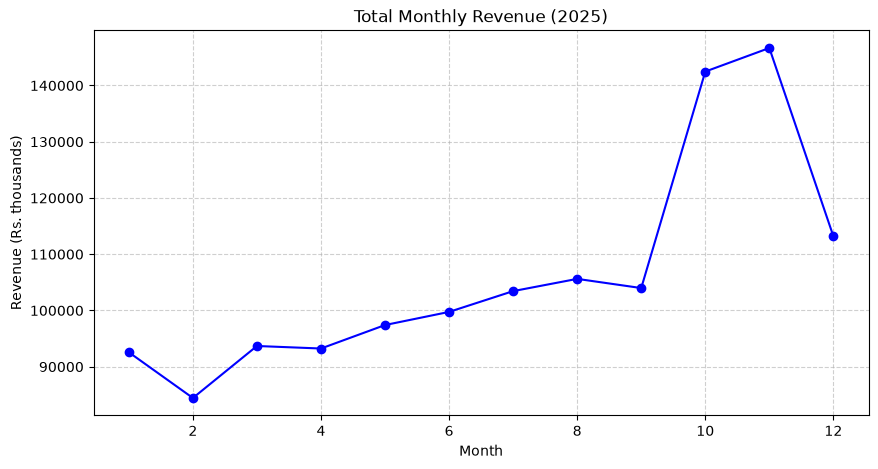

In [10]:
# task2
plt.figure(figsize=(10, 5))
df.groupby("Month")["Revenue"].sum().plot(marker="o", color="b", linestyle="-")
plt.title("Total Monthly Revenue (2025)")
plt.xlabel("Month")
plt.ylabel("Revenue (Rs. thousands)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

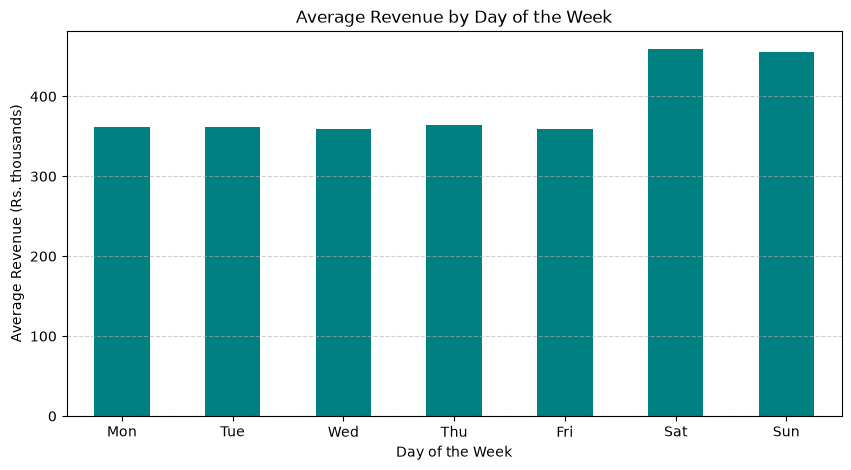

In [11]:
# task3
plt.figure(figsize=(10, 5))
df.groupby("Weekday")["Revenue"].mean().plot(kind="bar", color="teal")
plt.title("Average Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Average Revenue (Rs. thousands)")
plt.xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

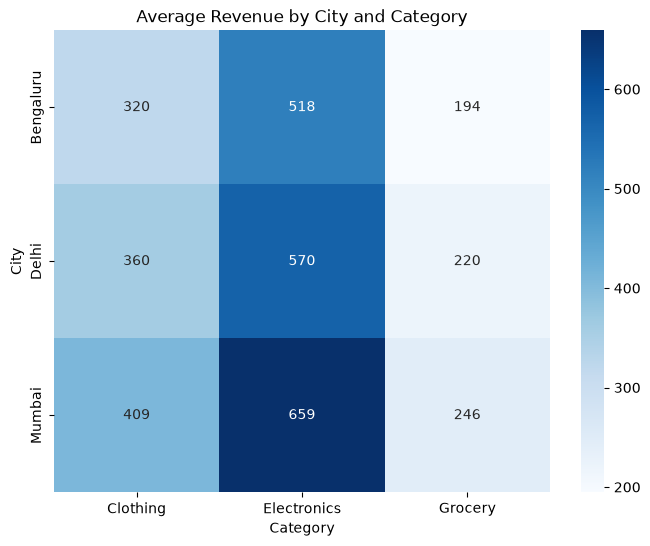

In [12]:
# tassk4
plt.figure(figsize=(8, 6))
pv = df.pivot_table(index="City", columns="Category", values="Revenue", aggfunc="mean")
sns.heatmap(pv, annot=True, fmt=".0f", cmap="Blues")
plt.title("Average Revenue by City and Category")
plt.xlabel("Category")
plt.ylabel("City")
plt.show()

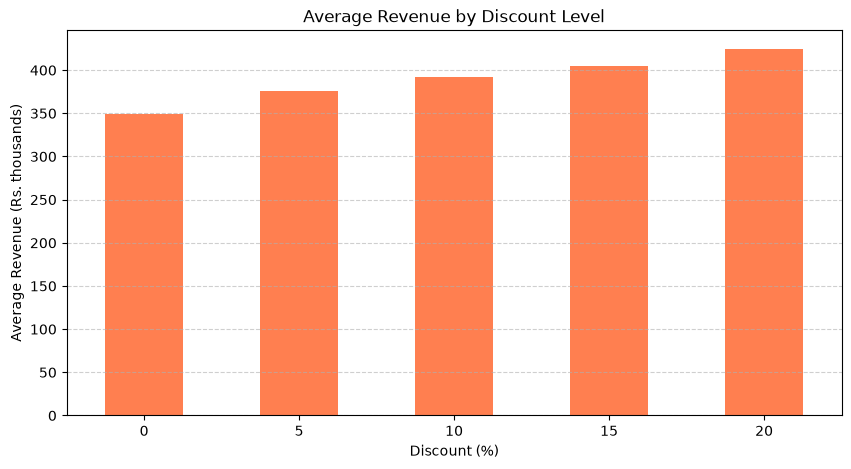

In [14]:
# task5
plt.figure(figsize=(10, 5))
df.groupby("Discount")["Revenue"].mean().plot(kind="bar", color="coral")
plt.title("Average Revenue by Discount Level")
plt.xlabel("Discount (%)")
plt.ylabel("Average Revenue (Rs. thousands)")
plt.xticks(rotation=0)
plt.grid(axis="y", linestyle="--", alpha=0.6)
plt.show()

In [15]:
# task6
fig = px.box(df, x="Category", y="Revenue", hover_data=["Date", "City"])
fig.show()

# Code cell (Remove outliers)
category_mean = df.groupby("Category")["Revenue"].transform("mean")
clean = df[df["Revenue"] <= 3 * category_mean]
print("Rows removed:", len(df) - len(clean))

Rows removed: 3


## Part B: Interactive Dashboard

In [16]:
# task7
# fig_a: Line chart of monthly revenue for each city
monthly = clean.groupby(["Month", "City"], as_index=False)["Revenue"].sum()
fig_a = px.line(monthly, x="Month", y="Revenue", color="City", markers=True, title="Monthly Revenue by City")

# fig_b: Bar chart of total revenue for each category
category_total = clean.groupby("Category", as_index=False)["Revenue"].sum()
fig_b = px.bar(category_total, x="Category", y="Revenue", color="Category", title="Total Revenue by Category")

# fig_c: Heatmap of average revenue by city and category
pv_clean = clean.pivot_table(index="City", columns="Category", values="Revenue", aggfunc="mean")
fig_c = px.imshow(pv_clean, text_auto=".0f", color_continuous_scale="Blues", title="Average Revenue: City vs Category")

# fig_d: Bar chart of average revenue for each discount level
discount_mean = clean.groupby("Discount", as_index=False)["Revenue"].mean()
fig_d = px.bar(discount_mean, x="Discount", y="Revenue", color="Discount", title="Average Revenue by Discount (%)")

fig_a.show()
fig_b.show()
fig_c.show()
fig_d.show()

In [17]:
# task8
from plotly.subplots import make_subplots

dash = make_subplots(rows=2, cols=2, subplot_titles=(
    "Monthly revenue by city", "Total revenue by category",
    "Average revenue: city vs category", "Average revenue by discount (%)"))

for trace in fig_a.data: dash.add_trace(trace, row=1, col=1)
for trace in fig_b.data: dash.add_trace(trace, row=1, col=2)
for trace in fig_c.data: dash.add_trace(trace, row=2, col=1)
for trace in fig_d.data: dash.add_trace(trace, row=2, col=2)

dash.update_coloraxes(showscale=False)
dash.update_layout(height=700, title_text="Retail Sales Dashboard", template="simple_white")

# Axis titles with units
dash.update_xaxes(title_text="Month", row=1, col=1)
dash.update_yaxes(title_text="Revenue (Rs. Thousands)", row=1, col=1)
dash.update_xaxes(title_text="Category", row=1, col=2)
dash.update_yaxes(title_text="Total Revenue (Rs. Thousands)", row=1, col=2)

dash.write_html("sales_dashboard.html")
dash.show()